# Working with NISAR GUNW products

A **GUNW** (Geocoded Unwrapped Interferogram) is a NISAR Level-2 product. It compares two radar images of the same place taken on different dates. The **phase difference** between them tells us how much the ground moved towards or away from the satellite.

The raw phase also contains signals that are *not* ground motion, so we remove them:

| Signal | Cause | Where it comes from in this notebook |
|---|---|---|
| Ionosphere | Charged particles in the upper atmosphere | Stored directly in the GUNW file |
| Troposphere | Water vapour and air pressure in the lower atmosphere | 3-D "metadata cube" in the GUNW file, evaluated at ground height |
| Solid Earth tide | The ground itself rises and falls with the tides | 3-D "metadata cube" in the GUNW file, evaluated at ground height |

**What this notebook does**

1. Read the main layers (phase, coherence, ionosphere, connected components).
2. Build a mask that removes water and bad pixels.
3. Download a DEM (ground-height map) on the same grid as the GUNW.
4. Use the DEM to compute troposphere and solid Earth tide corrections.
5. Subtract all corrections from the phase.
6. Save the results as GeoTIFFs (open them in QGIS/ArcGIS) and plot them.

**Needed packages:** `h5py`, `numpy`, `scipy`, `matplotlib`, `rasterio`, `dem_stitcher`

## 1. Setup

In [1]:
import os
import h5py
import numpy as np
import matplotlib.pyplot as plt
import rasterio
from rasterio.transform import from_origin
from rasterio.warp import reproject, transform_bounds, Resampling
from scipy.interpolate import RegularGridInterpolator
from dem_stitcher.stitcher import stitch_dem

### Settings
Change these if you use a different file. Everything else in the notebook works from them.

To download the example file, you need a free [NASA Earthdata](https://urs.earthdata.nasa.gov/) account. Uncomment the `wget` line, or download the file in your browser and put it next to this notebook.

In [2]:
gunw_file = "nisar_test/NISAR_L2_PR_GUNW_022_162_A_007_023_4000_SH_20260613T100656_20260613T100731_20260625T100655_20260625T100730_P05023_N_F_J_001.h5"
polarization = "HH"
output_dir = "output_files"

# !wget https://nisar.asf.earthdatacloud.nasa.gov/NISAR/NISAR_L2_GUNW_PROVISIONAL_V1/{gunw_file[:-3]}/{gunw_file}

os.makedirs(output_dir, exist_ok=True)

# Locations of the layers inside the HDF5 file
GRID = "/science/LSAR/GUNW/grids/frequencyA/unwrappedInterferogram"
LAYERS = f"{GRID}/{polarization}"
CUBE = "/science/LSAR/GUNW/metadata/radarGrid"

## 2. Read the main layers

| Layer | Meaning |
|---|---|
| `unwrappedPhase` | Phase difference between the two dates (radians) |
| `coherenceMagnitude` | Quality of the phase, from 0 (noise) to 1 (very reliable) |
| `ionospherePhaseScreen` | Estimated ionospheric phase (radians) |
| `connectedComponents` | Regions that were unwrapped together. Pixels with label 0 were not unwrapped reliably |
| `xCoordinates`, `yCoordinates` | Map coordinates of each pixel centre (metres, in the projection given by `projection`) |

In [3]:
with h5py.File(gunw_file, "r") as f:
    phase       = f[f"{LAYERS}/unwrappedPhase"][:]
    coherence   = f[f"{LAYERS}/coherenceMagnitude"][:]
    iono        = f[f"{LAYERS}/ionospherePhaseScreen"][:]
    conn_comp   = f[f"{LAYERS}/connectedComponents"][:]
    x           = f[f"{LAYERS}/xCoordinates"][:]
    y           = f[f"{LAYERS}/yCoordinates"][:]
    dx          = float(f[f"{LAYERS}/xCoordinateSpacing"][()])
    dy          = float(f[f"{LAYERS}/yCoordinateSpacing"][()])   # negative: rows go from north to south
    epsg        = int(f[f"{LAYERS}/projection"][()])
    mask_values = f[f"{GRID}/mask"][:]

rows, cols = phase.shape
crs = f"EPSG:{epsg}"

# Map position of the grid. Coordinates are pixel centres, so the outer edge is half a pixel further out.
transform = from_origin(x[0] - dx / 2, y[0] - dy / 2, dx, abs(dy))
bounds = (x.min() - dx / 2, y.min() - abs(dy) / 2, x.max() + dx / 2, y.max() + abs(dy) / 2)  # (west, south, east, north)
extent = [bounds[0], bounds[2], bounds[1], bounds[3]]  # used by matplotlib to label the axes in metres

print(f"Grid: {rows} rows x {cols} columns, pixel size {dx:.0f} m, projection {crs}")

Grid: 4149 rows x 4239 columns, pixel size 80 m, projection EPSG:32619


**Wrapping:** unwrapped phase can be any number of radians. *Wrapping* folds it back into the range −π to +π. The result looks like coloured fringes, and each fringe is one cycle of phase. This makes small changes easier to see in a plot.

In [4]:
def wrap(p):
    # Fold phase into the range -pi to +pi.
    return np.angle(np.exp(1j * p))

## 3. Build a mask of valid pixels

The GUNW `mask` layer packs several flags into one 32-bit number per pixel:

| Bits | Content |
|---|---|
| 0–7 | A 3-digit number. Hundreds digit = 1 means **water**. Tens digit = subswath of the first (reference) image. Units digit = subswath of the second (secondary) image. Subswath **0** means no data. |
| 8–15 | Problems found in the secondary image (0 = none) |
| 16–23 | Problems found in the reference image (0 = none) |

A pixel is **valid** if it is not water, both images have data there, and neither image has a problem.

In [5]:
low_byte    = mask_values & 0xFF
is_water    = (low_byte // 100) == 1
ref_swath   = (low_byte // 10) % 10
sec_swath   = low_byte % 10
sec_problem = (mask_values >> 8) & 0xFF
ref_problem = (mask_values >> 16) & 0xFF

valid = (~is_water) & (ref_swath > 0) & (sec_swath > 0) & (ref_problem == 0) & (sec_problem == 0)

print(f"Valid pixels: {valid.mean():.1%}")

Valid pixels: 27.7%


## 4. Get a DEM on the GUNW grid

The troposphere and solid Earth tide corrections depend on **ground height**, so we need a DEM (Digital Elevation Model).

1. Convert the GUNW extent to latitude/longitude, because DEM tiles are stored that way.
2. Download the 30 m Copernicus DEM (`glo_30`) for that area. We use heights above the **ellipsoid**, the same height reference the GUNW uses.
3. Resample the DEM onto the GUNW grid, so every DEM pixel matches a GUNW pixel exactly.

In [6]:
# 1. GUNW extent in latitude/longitude (west, south, east, north)
lonlat_bounds = transform_bounds(crs, "EPSG:4326", *bounds, densify_pts=21)
print("Lat/lon extent:", [round(v, 3) for v in lonlat_bounds])

# 2. Download the DEM tiles and join them into one array (this can take a few minutes)
dem_raw, dem_profile = stitch_dem(
    list(lonlat_bounds),
    dem_name="glo_30",
    dst_ellipsoidal_height=True,
    dst_area_or_point="Point",
)

# 3. Resample onto the GUNW grid
dem = np.full((rows, cols), np.nan, dtype="float32")
reproject(
    source=dem_raw,
    destination=dem,
    src_transform=dem_profile["transform"],
    src_crs=dem_profile["crs"],
    dst_transform=transform,
    dst_crs=crs,
    resampling=Resampling.bilinear,
    dst_nodata=np.nan,
)
print(f"DEM on GUNW grid: {dem.shape}, heights {np.nanmin(dem):.0f} to {np.nanmax(dem):.0f} m")

Lat/lon extent: [-69.824, 9.346, -66.705, 12.355]


Reading tile metadata:   0%|                            | 0/15 [00:00<?, ?it/s]/Users/nafissk/miniconda3/envs/insar-env/lib/python3.11/site-packages/dem_stitcher/rio_window.py:146: RuntimeWarning: Requesting extent beyond raster bounds of [-70.00013888888888, 11.00013888888889, -69.00013888888888, 12.00013888888889]. Shrinking bounds in raster crs to (-69.82414755943846, 11.00013888888889, -69.00013888888888, 12.00013888888889).
  warn(
Reading tile imagery: 100%|████████████████████| 15/15 [00:10<00:00,  1.39it/s]


DEM on GUNW grid: (4149, 4239), heights -36 to 2717 m


## 5. Troposphere and solid Earth tide corrections

These corrections are stored as **3-D cubes**: a coarse grid in x and y, repeated at several heights. To get the value for each pixel, we read the cube at that pixel's position **and** at its ground height from the DEM (3-D linear interpolation).

The total tropospheric delay has two parts: **wet** (water vapour) and **hydrostatic** (dry air pressure). We add them together.

In [7]:
def cube_to_grid(cube_name):
    # Read a 3-D correction cube and evaluate it at every GUNW pixel, at that pixel's DEM height.
    with h5py.File(gunw_file, "r") as f:
        cube   = f[f"{CUBE}/{cube_name}"][:]            # shape: (height, y, x)
        cube_z = f[f"{CUBE}/heightAboveEllipsoid"][:]
        cube_y = f[f"{CUBE}/yCoordinates"][:]
        cube_x = f[f"{CUBE}/xCoordinates"][:]

    interpolate = RegularGridInterpolator(
        (cube_z, cube_y, cube_x), cube, method="linear", bounds_error=False, fill_value=np.nan
    )

    X, Y = np.meshgrid(x, y)
    points = np.column_stack([dem.ravel(), Y.ravel(), X.ravel()])
    return interpolate(points).reshape(rows, cols).astype("float32")


tropo = cube_to_grid("wetTroposphericPhaseScreen") + cube_to_grid("hydrostaticTroposphericPhaseScreen")
solid_earth_tide = cube_to_grid("slantRangeSolidEarthTidesPhase")

## 6. Apply the corrections

We subtract the corrections one at a time, so we can see what each one does. After that, invalid pixels are set to NaN (shown as blank in plots).

In [8]:
phase_iono_corrected = phase - iono
phase_corrected      = phase - iono - tropo - solid_earth_tide

def apply_mask(a):
    return np.where(valid, a, np.nan)

phase_masked                = apply_mask(phase)
phase_iono_corrected_masked = apply_mask(phase_iono_corrected)
phase_corrected_masked      = apply_mask(phase_corrected)

## 7. Save as GeoTIFFs

Every layer is saved on the same map grid, so they line up when you open them in a GIS. To save another layer, add it to the `layers` dictionary.

In [9]:
def save_geotiff(data, name, nodata=np.nan):
    path = os.path.join(output_dir, f"{name}.tif")
    with rasterio.open(
        path, "w", driver="GTiff",
        height=rows, width=cols, count=1, dtype=data.dtype,
        crs=crs, transform=transform, nodata=nodata,
    ) as dst:
        dst.write(data, 1)
    print("Saved", path)


layers = {
    "unwrapped_phase":        phase,
    "coherence":              coherence,
    "ionosphere":             iono,
    "troposphere":            tropo,
    "solid_earth_tide":       solid_earth_tide,
    "dem":                    dem,
    "phase_corrected":        phase_corrected,
    "phase_corrected_masked": phase_corrected_masked,
}
for name, data in layers.items():
    save_geotiff(data.astype("float32"), name)

# Integer layers need a whole-number "no data" value instead of NaN
save_geotiff(conn_comp, "connected_components", nodata=65535)
save_geotiff(valid.astype("uint8"), "valid_mask", nodata=None)

Saved output_files/unwrapped_phase.tif
Saved output_files/coherence.tif
Saved output_files/ionosphere.tif
Saved output_files/troposphere.tif
Saved output_files/solid_earth_tide.tif
Saved output_files/dem.tif
Saved output_files/phase_corrected.tif
Saved output_files/phase_corrected_masked.tif
Saved output_files/connected_components.tif
Saved output_files/valid_mask.tif


## 8. Plots

One small helper draws any number of maps side by side, with axes in metres.

In [10]:
def show(maps, cmap="RdBu", label="Phase (radians)", vmin=None, vmax=None):
    # maps: list of (array, title) pairs, drawn next to each other.
    fig, axes = plt.subplots(1, len(maps), figsize=(6 * len(maps), 6), squeeze=False)
    for ax, (data, title) in zip(axes[0], maps):
        im = ax.imshow(data, cmap=cmap, extent=extent, vmin=vmin, vmax=vmax, interpolation="nearest")
        ax.set_title(title, fontsize=11)
        ax.set_xlabel("Easting (m)")
        ax.set_ylabel("Northing (m)")
        fig.colorbar(im, ax=ax, label=label, shrink=0.7)
    plt.tight_layout()
    plt.show()

### Unwrapped phase and coherence
Bright areas in the coherence map have reliable phase. Dark areas (water, dense vegetation, changed surfaces) are noisy.

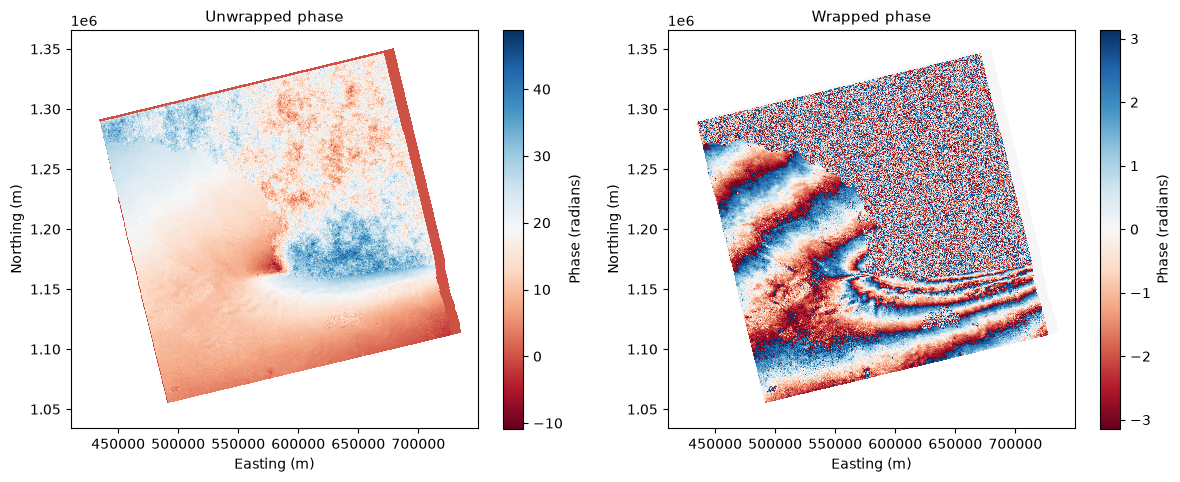

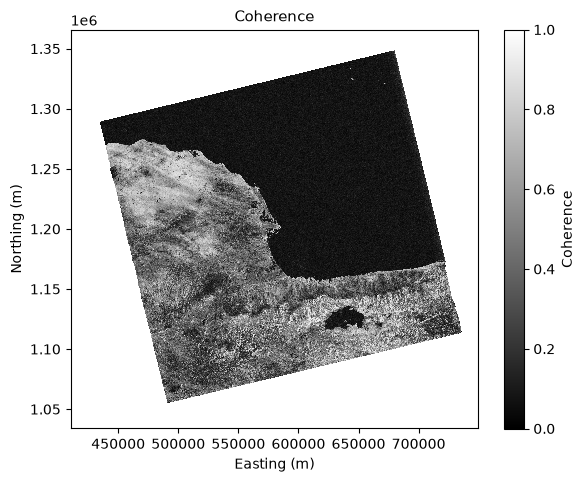

In [11]:
show([(phase, "Unwrapped phase"), (wrap(phase), "Wrapped phase")])
show([(coherence, "Coherence")], cmap="gray", label="Coherence", vmin=0, vmax=1)

### Ionosphere

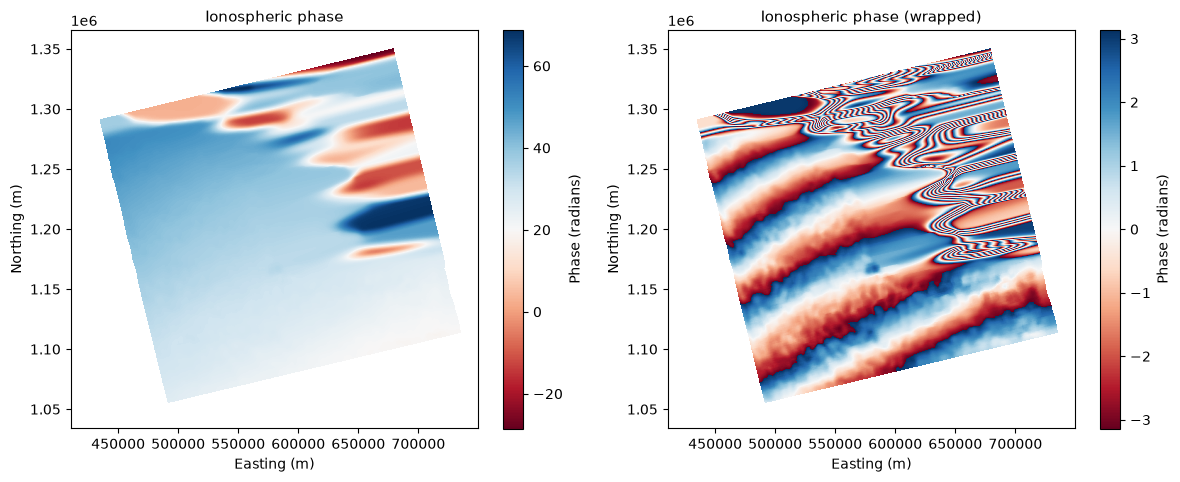

In [12]:
show([(iono, "Ionospheric phase"), (wrap(iono), "Ionospheric phase (wrapped)")])

### Troposhere and solid earth tide

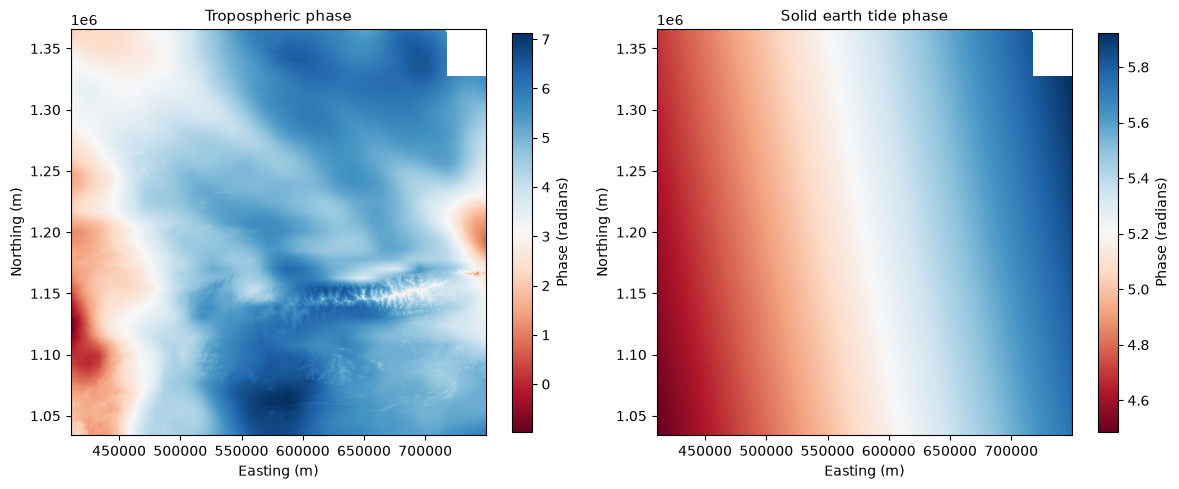

In [13]:
show([(tropo, "Tropospheric phase"), (solid_earth_tide, "Solid earth tide phase")])

### Effect of the mask

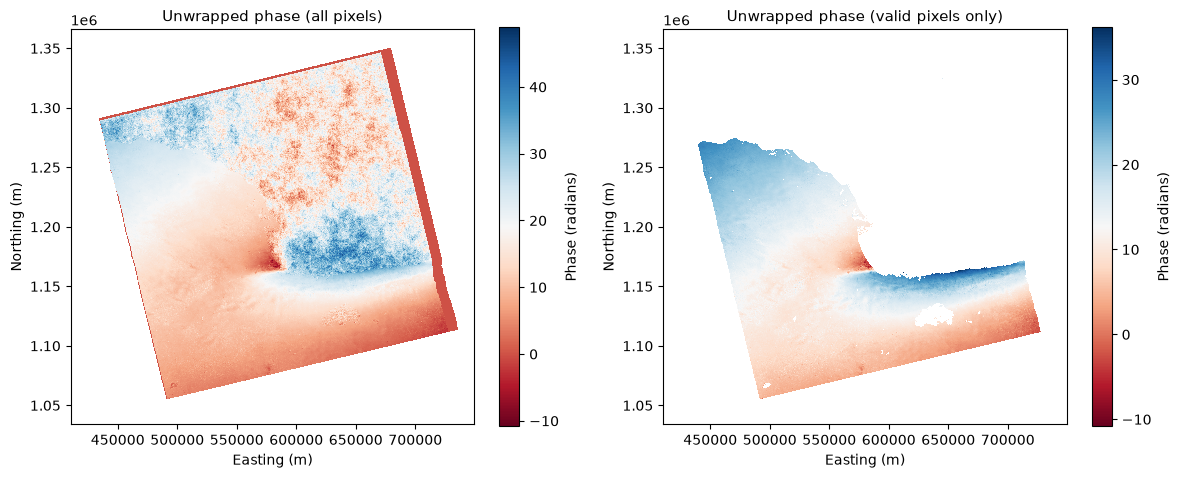

In [14]:
show([(phase, "Unwrapped phase (all pixels)"), (phase_masked, "Unwrapped phase (valid pixels only)")])

### Effect of the corrections
Each panel removes one more source of noise. Fewer fringes after a correction means that correction removed signal that was not ground motion.

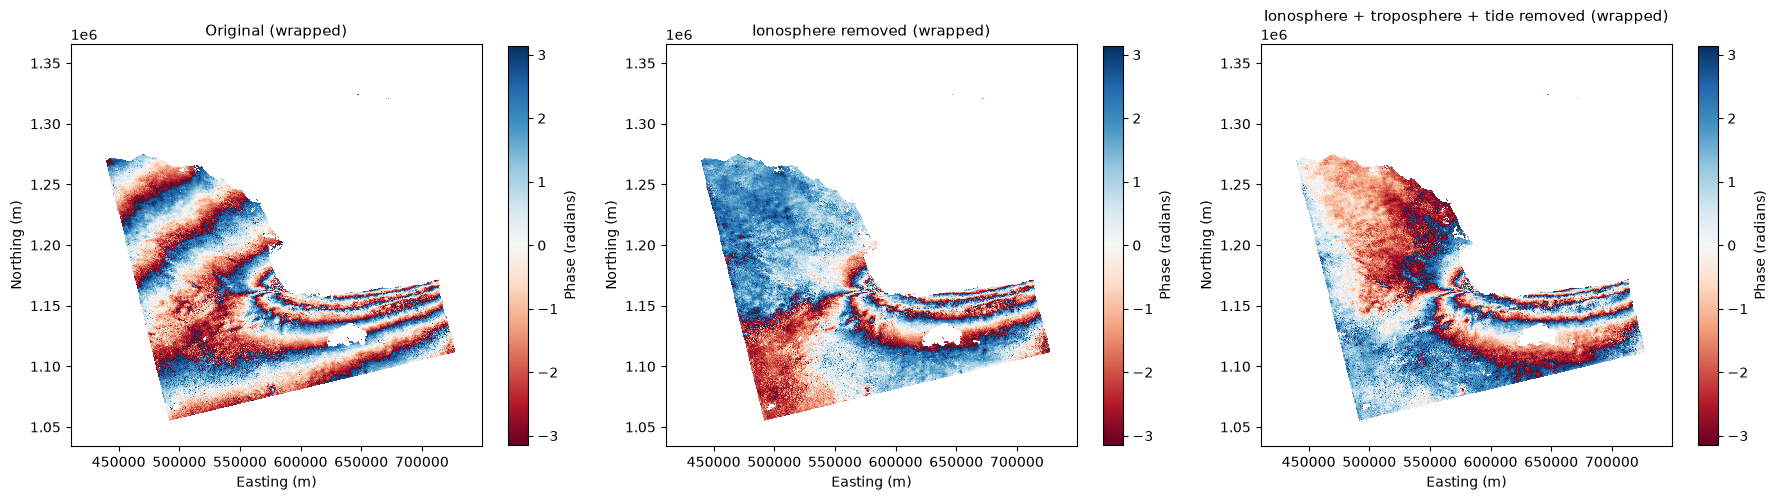

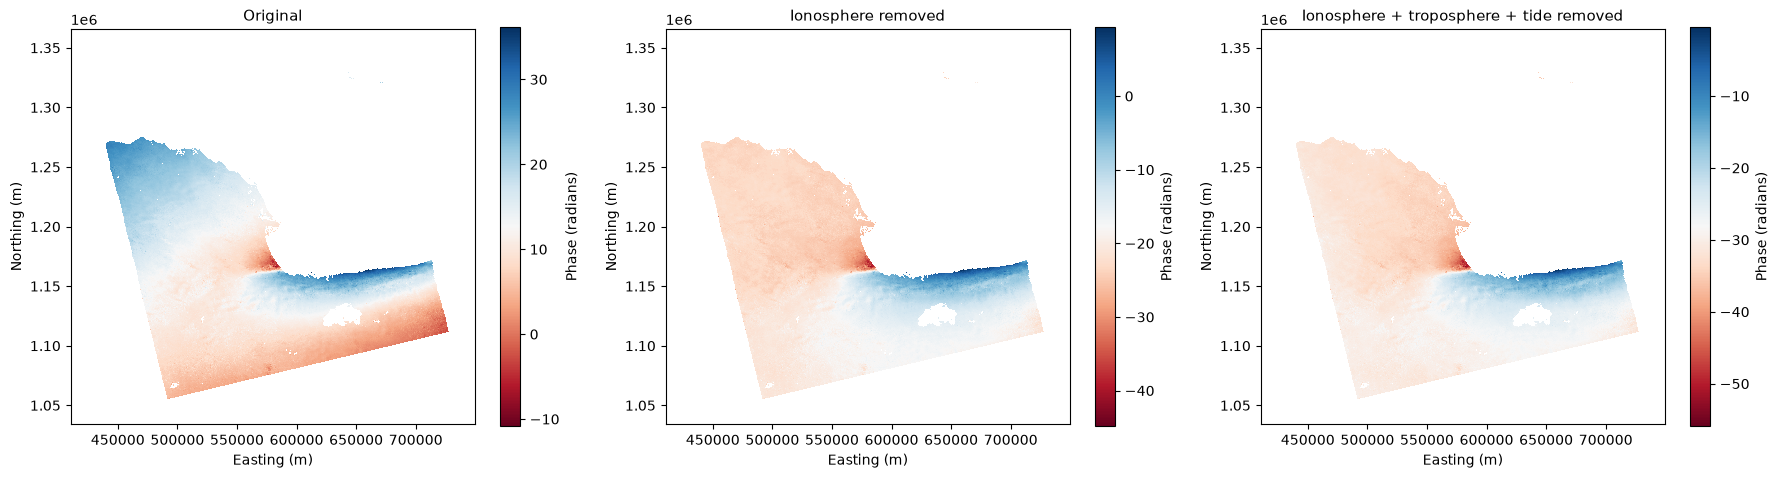

In [15]:
steps = [
    (phase_masked,                "Original"),
    (phase_iono_corrected_masked, "Ionosphere removed"),
    (phase_corrected_masked,      "Ionosphere + troposphere + tide removed"),
]

show([(wrap(p), title + " (wrapped)") for p, title in steps])
show(steps)